In [1]:
# ============================================================
# CELL 1 — IMPORT LIBRARIES
# ============================================================

import os
from ultralytics import YOLO
from PIL import Image

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ============================================================
# CELL 2 — DEFINE SAVED MODEL PATH
# ============================================================

model_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\trained_models\apple_ripeness_model\apple_ripeness_best.pt"

print("Model path:")
print(model_path)

print()
print("Model file exists:", os.path.isfile(model_path))

Model path:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\trained_models\apple_ripeness_model\apple_ripeness_best.pt

Model file exists: True


In [3]:
# ============================================================
# CELL 3 — LOAD SAVED APPLE RIPENESS MODEL
# ============================================================

# Load the trained YOLO model
trained_model = YOLO(model_path)

print("Model loaded successfully.")
print()

print("Task:", trained_model.task)

print()
print("Class names:")

for class_id, class_name in trained_model.names.items():
    print(f"{class_id} -> {class_name}")

Model loaded successfully.

Task: detect

Class names:
0 -> overripe
1 -> ripe
2 -> unripe


In [4]:
# ============================================================
# CELL 4 — DEFINE TEST IMAGE PATH
# ============================================================

test_image_path = r"unripe_apple.png"

print("Test image path:")
print(test_image_path)

print()
print("Image file exists:", os.path.isfile(test_image_path))

Test image path:
unripe_apple.png

Image file exists: True


Image size:
(451, 472)

Test image:


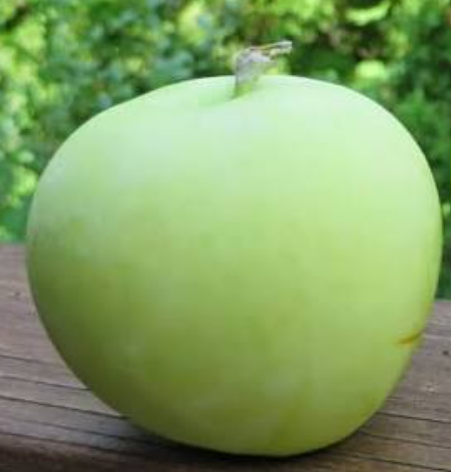

In [5]:
# ============================================================
# CELL 5 — DISPLAY TEST IMAGE
# ============================================================

test_image = Image.open(test_image_path)

print("Image size:")
print(test_image.size)

print()
print("Test image:")

display(test_image)

Original image mode : RGBA
Grayscale mode      : L
YOLO input mode     : RGB

Displaying grayscale image:


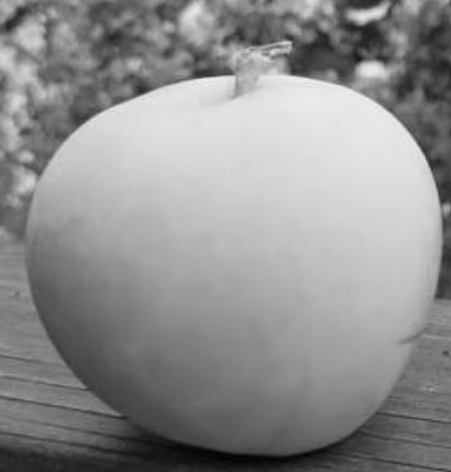

In [6]:
# ============================================================
# CELL 12 — CONVERT COLOR IMAGE TO GRAYSCALE
# ============================================================

# Convert the color image to grayscale
grayscale_image = test_image.convert("L")

# Convert back to RGB because YOLO normally expects a 3-channel image
grayscale_rgb_image = grayscale_image.convert("RGB")

print("Original image mode :", test_image.mode)
print("Grayscale mode      :", grayscale_image.mode)
print("YOLO input mode     :", grayscale_rgb_image.mode)

print()
print("Displaying grayscale image:")

display(grayscale_rgb_image)

In [7]:
# ============================================================
# CELL 6 — RUN SAVED MODEL ON TEST IMAGE
# ============================================================

prediction_results = trained_model.predict(
    source=grayscale_rgb_image,
    imgsz=640,
    conf=0.25,
    device="cpu"
)

print("Prediction completed successfully.")
print()
print("Number of result objects:", len(prediction_results))


0: 640x640 1 unripe, 295.5ms
Speed: 32.8ms preprocess, 295.5ms inference, 5.5ms postprocess per image at shape (1, 3, 640, 640)
Prediction completed successfully.

Number of result objects: 1


In [8]:
# ============================================================
# CELL 7 — EXTRACT RIPENESS AND CONFIDENCE
# ============================================================

result = prediction_results[0]

if result.boxes is not None and len(result.boxes) > 0:

    print("Detected objects:", len(result.boxes))
    print()

    for i, box in enumerate(result.boxes):

        # Class ID
        class_id = int(box.cls[0].item())

        # Ripeness class name
        class_name = trained_model.names[class_id]

        # Confidence score
        confidence = float(box.conf[0].item())

        print(f"Object {i + 1}")
        print("----------------------------")
        print("Class ID   :", class_id)
        print("Ripeness   :", class_name)
        print(f"Confidence : {confidence:.4f}")
        print()

else:
    print("No apple detected.")

Detected objects: 1

Object 1
----------------------------
Class ID   : 2
Ripeness   : unripe
Confidence : 0.7280



In [9]:
# ============================================================
# CELL 8 — EXTRACT BOUNDING BOX AND CENTER (u, v)
# ============================================================

if result.boxes is not None and len(result.boxes) > 0:

    print("Detected apple information:")
    print()

    for i, box in enumerate(result.boxes):

        # Bounding box coordinates
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        # Center pixel coordinates
        u = (x1 + x2) / 2
        v = (y1 + y2) / 2

        # Image dimensions
        image_width, image_height = test_image.size

        print(f"Object {i + 1}")
        print("----------------------------")
        print(f"Bounding box:")
        print(f"  x1 = {x1:.2f}")
        print(f"  y1 = {y1:.2f}")
        print(f"  x2 = {x2:.2f}")
        print(f"  y2 = {y2:.2f}")
        print()
        print(f"Center pixel:")
        print(f"  u = {u:.2f}")
        print(f"  v = {v:.2f}")
        print()
        print(f"Image size: {image_width} x {image_height}")

else:
    print("No apple detected.")

Detected apple information:

Object 1
----------------------------
Bounding box:
  x1 = 8.51
  y1 = 1.48
  x2 = 451.00
  y2 = 443.18

Center pixel:
  u = 229.76
  v = 222.33

Image size: 451 x 472


Detection:
  Ripeness   : unripe
  Confidence : 0.7280
  Center (u,v): (229.76, 222.33)


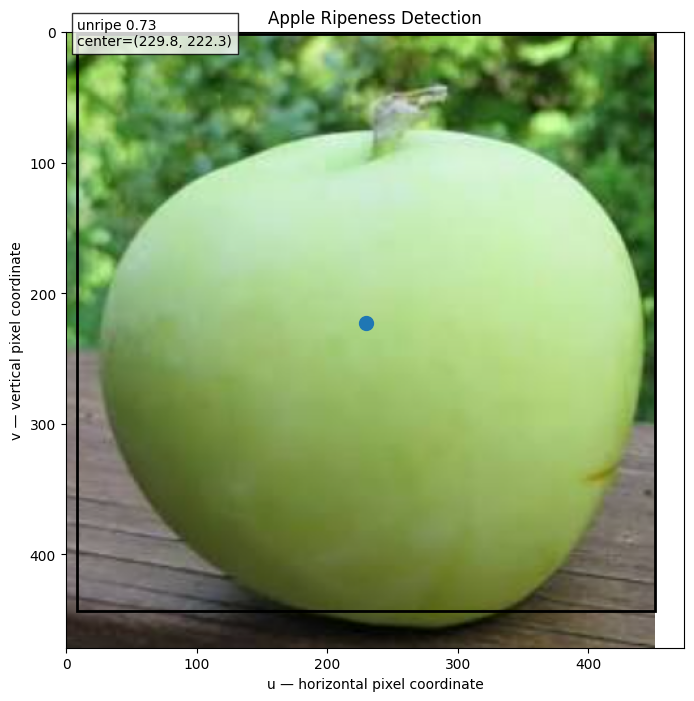

In [10]:
# ============================================================
# CELL 9 — DISPLAY DETECTION WITH CENTER POINT
# ============================================================

import matplotlib.pyplot as plt

# Create a copy of the image for plotting
display_image = test_image.copy()

plt.figure(figsize=(10, 8))
plt.imshow(display_image)

if result.boxes is not None and len(result.boxes) > 0:

    for box in result.boxes:

        # Bounding box
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        # Class and confidence
        class_id = int(box.cls[0].item())
        class_name = trained_model.names[class_id]
        confidence = float(box.conf[0].item())

        # Center coordinates
        u = (x1 + x2) / 2
        v = (y1 + y2) / 2

        # Draw bounding box
        rectangle = plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            linewidth=2
        )

        plt.gca().add_patch(rectangle)

        # Draw center point
        plt.scatter(
            u,
            v,
            s=100,
            marker="o"
        )

        # Label
        label = (
            f"{class_name} "
            f"{confidence:.2f}\n"
            f"center=({u:.1f}, {v:.1f})"
        )

        plt.text(
            x1,
            max(y1 - 10, 10),
            label,
            fontsize=10,
            bbox=dict(facecolor="white", alpha=0.8)
        )

        print("Detection:")
        print(f"  Ripeness   : {class_name}")
        print(f"  Confidence : {confidence:.4f}")
        print(f"  Center (u,v): ({u:.2f}, {v:.2f})")

else:
    print("No apple detected.")

plt.title("Apple Ripeness Detection")
plt.xlabel("u — horizontal pixel coordinate")
plt.ylabel("v — vertical pixel coordinate")
plt.show()

Apple Detection
----------------------------
Ripeness   : unripe
Confidence : 0.7280

Target Position [3x1]
X = 229.76
Y = 222.33
Z = 0.40

Controller input:
[229.76]
[222.33]
[0.40]


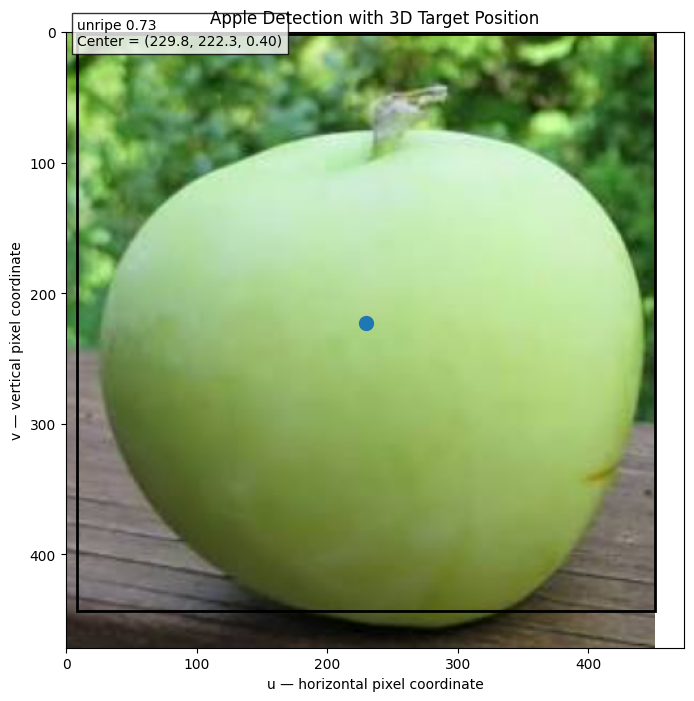

In [11]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# Assumed average apple depth
# --------------------------------------------------
average_apple_Z = 0.40   # metres

display_image = test_image.copy()

plt.figure(figsize=(10, 8))
plt.imshow(display_image)

if result.boxes is not None and len(result.boxes) > 0:

    for box in result.boxes:

        # Bounding box
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        # Detection information
        class_id = int(box.cls[0].item())
        class_name = trained_model.names[class_id]
        confidence = float(box.conf[0].item())

        # --------------------------------------------------
        # Apple centre in image coordinates
        # --------------------------------------------------
        u = (x1 + x2) / 2
        v = (y1 + y2) / 2

        # --------------------------------------------------
        # 3D target position
        # Here we use image centre coordinates + assumed depth
        # --------------------------------------------------
        X = u
        Y = v
        Z = average_apple_Z

        # --------------------------------------------------
        # Display bounding box
        # --------------------------------------------------
        rectangle = plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            linewidth=2
        )

        plt.gca().add_patch(rectangle)

        # Centre point
        plt.scatter(u, v, s=100, marker="o")

        # Label
        label = (
            f"{class_name} {confidence:.2f}\n"
            f"Center = ({X:.1f}, {Y:.1f}, {Z:.2f})"
        )

        plt.text(
            x1,
            max(y1 - 10, 10),
            label,
            fontsize=10,
            bbox=dict(facecolor="white", alpha=0.8)
        )

        # --------------------------------------------------
        # Print final 3 values
        # --------------------------------------------------
        print("Apple Detection")
        print("----------------------------")
        print(f"Ripeness   : {class_name}")
        print(f"Confidence : {confidence:.4f}")
        print()
        print("Target Position [3x1]")
        print(f"X = {X:.2f}")
        print(f"Y = {Y:.2f}")
        print(f"Z = {Z:.2f}")
        print()
        print("Controller input:")
        print(f"[{X:.2f}]")
        print(f"[{Y:.2f}]")
        print(f"[{Z:.2f}]")

else:
    print("No apple detected.")

plt.title("Apple Detection with 3D Target Position")
plt.xlabel("u — horizontal pixel coordinate")
plt.ylabel("v — vertical pixel coordinate")
plt.show()